<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/imbalanced%20data/seminar_note_6_5_imbalance2balance_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **비대칭 데이터를 무작위로 추출하여 대칭데이터로 만들기**

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt

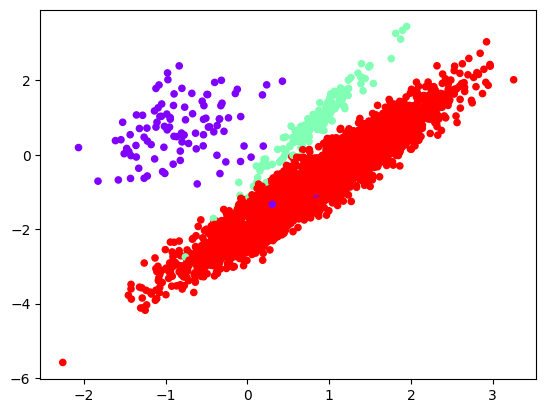

In [2]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=5000, n_features=2, n_informative=2,
                           n_redundant=0, n_repeated=0, n_classes=3,
                           n_clusters_per_class=1,
                           weights=[0.02, 0.03, 0.95],
                           class_sep=0.8, random_state=0)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='rainbow')

In [3]:
from collections import Counter
Counter(y)

Counter({np.int64(2): 4720, np.int64(1): 166, np.int64(0): 114})

In [4]:
# @title **1. 원래 데이터 학습모델 성능지표**
from sklearn.svm import LinearSVC
from sklearn import model_selection
clf = LinearSVC()
kf = model_selection.KFold(n_splits=3, shuffle=True, random_state=11)

model_selection.cross_validate(clf, X, y, scoring='recall_macro', cv=kf)

{'fit_time': array([0.0046258 , 0.0044837 , 0.00384879]),
 'score_time': array([0.00331998, 0.00288939, 0.00298166]),
 'test_score': array([0.73521166, 0.74912648, 0.75495495])}

In [5]:
model_selection.cross_val_score(clf, X, y, scoring='recall_macro', cv=kf)

array([0.73521166, 0.74912648, 0.75495495])

In [6]:
# @title **2. 원래 데이터를 가장 적은 비중과 동일하게 훈련데이터로 학습모델 생성 후 성능지표**
import numpy as np
from sklearn.model_selection import cross_val_score, cross_validate


# 1. 동등한 비율로 언더샘플링_무작위 sampling (학습 데이터 구성)
unique_classes, counts = np.unique(y, return_counts=True)
min_class_count = np.min(counts)

np.random.seed(0)
train_indices = []

for c in unique_classes:
    cls_indices = np.where(y == c)[0]
    sampled_indices = np.random.choice(cls_indices, size=min_class_count, replace=False)
    train_indices.extend(sampled_indices)

train_indices = np.array(train_indices)
X_train = X[train_indices]
y_train = y[train_indices]

print("=== [1] 훈련 데이터 클래스 분포 (동등 비중) ===")
print(f"전체 샘플 수: {len(y_train)}개\n")
for c in unique_classes:
    cnt = np.sum(y_train == c)
    print(f"클래스 {c}: {cnt}개 ({cnt/len(y_train)*100:.2f}%)")


=== [1] 훈련 데이터 클래스 분포 (동등 비중) ===
전체 샘플 수: 342개

클래스 0: 114개 (33.33%)
클래스 1: 114개 (33.33%)
클래스 2: 114개 (33.33%)


In [7]:
# 2. 모델 정의 (SVC)
clf = LinearSVC()

# 3. cross_val_score 사용 (scoring='recall_macro')
cv_scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='recall_macro')

print("\n=== [3] cross_val_score (recall_macro) ===\n")
print(f"Fold별 recall_macro 점수: {np.round(cv_scores, 4)}")
print(f"평균 recall_macro: {cv_scores.mean():.4f}")


=== [3] cross_val_score (recall_macro) ===

Fold별 recall_macro 점수: [0.8116 0.8986 0.8406 0.8656 0.8827]
평균 recall_macro: 0.8598


In [8]:
# 4. cross_validate 사용 (다중 평가 항목 및 학습/검증 시간 확인)
cv_results = cross_validate(
    clf, X_train, y_train, cv=5,
    scoring={'recall_macro': 'recall_macro'},
    return_train_score=True
)

print("\n=== [4] cross_validate 상세 결과 ===\n")
print(f"검증 recall_macro 평균: {cv_results['test_recall_macro'].mean():.4f}")
print(f"학습 recall_macro 평균: {cv_results['train_recall_macro'].mean():.4f}")


=== [4] cross_validate 상세 결과 ===

검증 recall_macro 평균: 0.8598
학습 recall_macro 평균: 0.8648


In [9]:
# 5. 원본 잔여 데이터(1,000개) 평가
remaining_indices = np.setdiff1d(np.arange(len(X)), train_indices)
val_indices = np.random.choice(remaining_indices, size=1000, replace=False)

X_val = X[val_indices]; y_val = y[val_indices]

clf.fit(X_train, y_train)
y_pred = clf.predict(X_val)

from sklearn.metrics import classification_report
print("\n=== [5] 원본 비중 반영 검증 데이터(1,000개) 최종 평가 ===\n")
print(classification_report(y_val, y_pred, labels=[0, 1, 2], target_names=['Class 0', 'Class 1', 'Class 2'], zero_division=0))

LinearSVC()


=== [5] 원본 비중 반영 검증 데이터(1,000개) 최종 평가 ===

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         0
     Class 1       0.10      0.80      0.18        10
     Class 2       1.00      0.92      0.96       990

    accuracy                           0.92      1000
   macro avg       0.37      0.57      0.38      1000
weighted avg       0.99      0.92      0.95      1000



Text(0.5, 1.0, 'Confusion Matrix (Validation Set)')

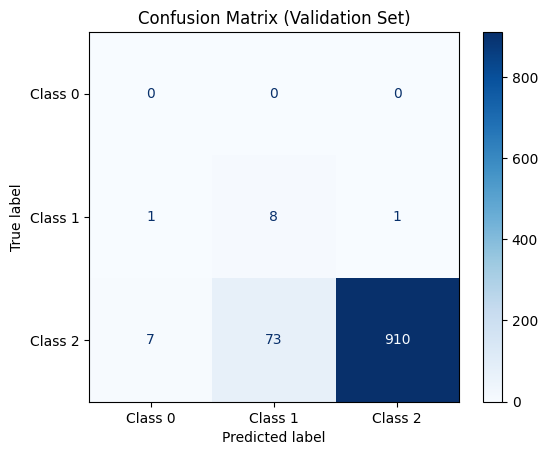

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1', 'Class 2'])
fig, ax = plt.subplots()
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix (Validation Set)")
plt.show()

[Text(0.5, 1.0, 'ROC Curve (AUROC)'),
 Text(0.5, 0, 'False Positive Rate'),
 Text(0, 0.5, 'True Positive Rate')]

[Text(0.5, 1.0, 'Precision-Recall Curve (PRAUC)'),
 Text(0.5, 0, 'Recall'),
 Text(0, 0.5, 'Precision')]

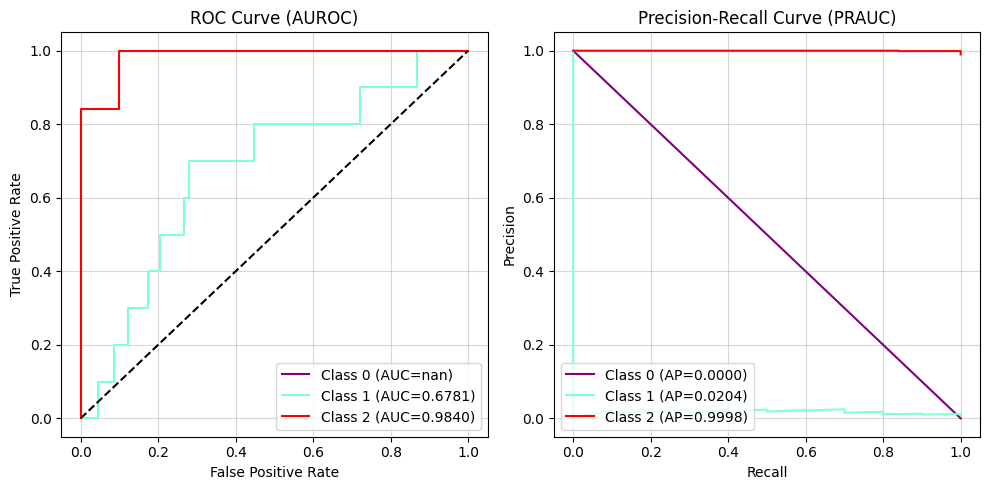

In [11]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

y_bin = label_binarize(y_val, classes=[0, 1, 2])
y_score = clf.decision_function(X_val)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

for i, c in enumerate(['purple', 'aquamarine', 'red']):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    ax1.plot(fpr, tpr, color=c, label=f'Class {i} (AUC={auc(fpr, tpr):.4f})')

    p, r, _ = precision_recall_curve(y_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_bin[:, i], y_score[:, i])
    ax2.plot(r, p, color=c, label=f'Class {i} (AP={ap:.4f})')

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set(title='ROC Curve (AUROC)', xlabel='False Positive Rate', ylabel='True Positive Rate')
ax2.set(title='Precision-Recall Curve (PRAUC)', xlabel='Recall', ylabel='Precision')
ax1.legend(loc='lower right'); ax2.legend(loc='lower left')
ax1.grid(alpha=0.5); ax2.grid(alpha=0.5)

plt.tight_layout()
plt.show()